# U-Net — Training Methodology

## 1. Weighted Cross-Entropy and Weight Map

Implementation and visualization of the pixel-wise
weighting strategy proposed by Ronneberger et al. (2015).

In [1]:
import sys
from pathlib import Path

import torch
import numpy as np
import matplotlib.pyplot as plt

# Locate the project root without a machine-specific path
cwd = Path.cwd().resolve()
ROOT = next(
    (folder for folder in (cwd, *cwd.parents)
     if (folder / "src" / "unet.py").is_file()),
    None
)
if ROOT is None:
    raise FileNotFoundError("Open the notebook from the U-Net project folder.")

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.unet import UNet
from src.loss import WeightedCrossEntropyLoss
from src.weight_map import compute_weight_map
from src.initialization import initialize_weights
from src.augmentation import elastic_deformation

(ROOT / "results").mkdir(parents=True, exist_ok=True)

torch.manual_seed(42)
device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

print("Project root:", ROOT)
print("Device:", device)
print("Imports successful.")

Project root: /Users/mac/Desktop/TPs/S3/Generative/Synthèse UNET
Device: mps
Imports successful.


In [2]:
size = 256

y, x = np.ogrid[:size, :size]

instance_mask = np.zeros(
    (size, size),
    dtype=np.int32
)

# Cell 1
instance_mask[
    (x - 80)**2 + (y - 100)**2 < 35**2
] = 1

# Cell 2
instance_mask[
    (x - 155)**2 + (y - 100)**2 < 35**2
] = 2

# Cell 3
instance_mask[
    (x - 118)**2 + (y - 175)**2 < 35**2
] = 3

binary_mask = (instance_mask > 0).astype(np.int64)

weight_map = compute_weight_map(
    instance_mask,
    w0=10,
    sigma=5
)

assert np.array_equal(np.unique(instance_mask), [0, 1, 2, 3])
print("Mask shape:", instance_mask.shape)
print("Labels:", np.unique(instance_mask))

Mask shape: (256, 256)
Labels: [0 1 2 3]


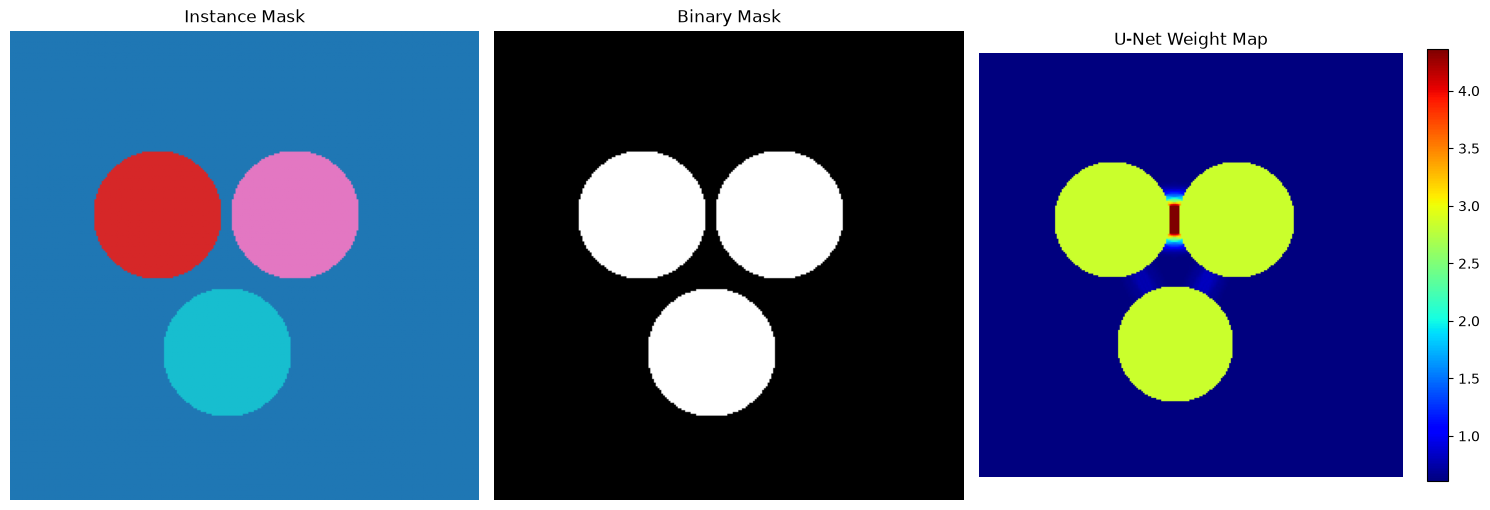

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(instance_mask, cmap="tab10", vmin=0, vmax=3)
axes[0].set_title("Instance Mask")

axes[1].imshow(binary_mask, cmap="gray")
axes[1].set_title("Binary Mask")

im = axes[2].imshow(weight_map, cmap="jet")
axes[2].set_title("U-Net Weight Map")

fig.colorbar(im, ax=axes[2], fraction=0.046)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [4]:
fig.savefig(
    ROOT / "results" / "weight_map_visualization.png",
    dpi=200,
    bbox_inches="tight"
)

print("Weight map saved successfully.")

Weight map saved successfully.


## 2. Elastic Data Augmentation

Random elastic deformations are applied to both
the input image and its corresponding segmentation mask.

Parameters:
- Control grid: 3 × 3
- Gaussian displacement standard deviation: 10 pixels
- Cubic interpolation for displacement fields
- Bilinear interpolation for images
- Nearest-neighbor interpolation for masks

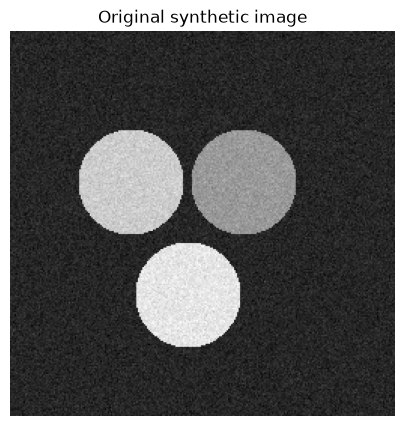

In [5]:
rng = np.random.default_rng(42)

image = np.full(
    instance_mask.shape,
    0.15,
    dtype=np.float32
)

image[instance_mask == 1] = 0.8
image[instance_mask == 2] = 0.6
image[instance_mask == 3] = 0.9

noise = rng.normal(0, 0.04, image.shape)

image = np.clip(image + noise, 0, 1).astype(np.float32)

plt.figure(figsize=(5, 5))
plt.imshow(image, cmap="gray", vmin=0, vmax=1)
plt.title("Original synthetic image")
plt.axis("off")
plt.show()

In [6]:
sigmas = [5, 10, 20]
augmented_samples = []

for sigma in sigmas:
    aug_image, aug_mask = elastic_deformation(
        image, instance_mask, sigma=sigma, seed=42
    )

    assert aug_image.shape == image.shape
    assert aug_mask.shape == instance_mask.shape
    assert np.isin(aug_mask, np.unique(instance_mask)).all()

    augmented_samples.append((aug_image, aug_mask))

print("Elastic augmentation samples:", len(augmented_samples))

Elastic augmentation samples: 3


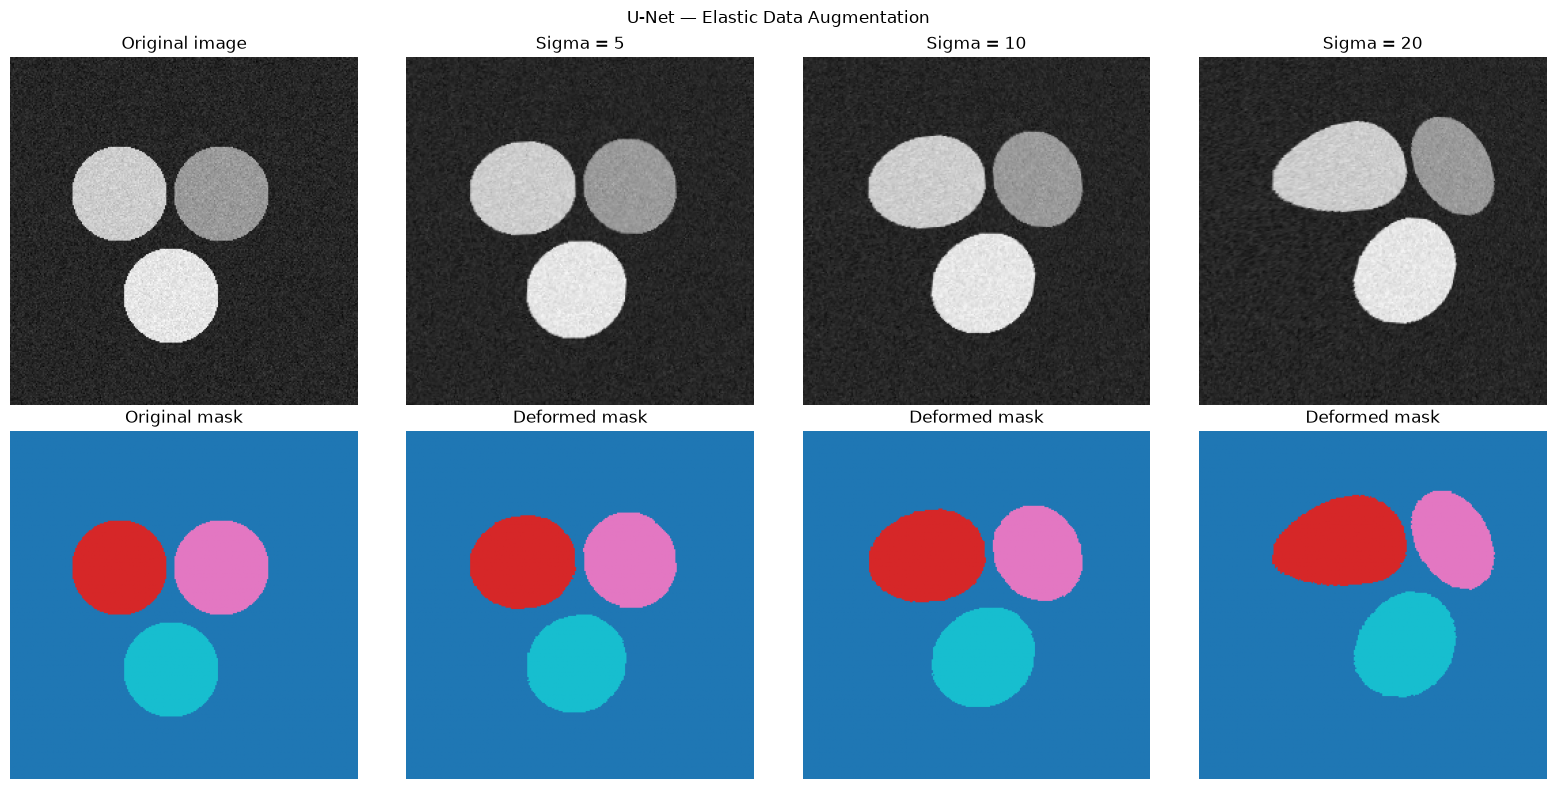

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

axes[0, 0].imshow(image, cmap="gray", vmin=0, vmax=1)
axes[0, 0].set_title("Original image")

axes[1, 0].imshow(instance_mask, cmap="tab10", vmin=0, vmax=3)
axes[1, 0].set_title("Original mask")

for i, (aug_image, aug_mask) in enumerate(augmented_samples, start=1):
    axes[0, i].imshow(aug_image, cmap="gray", vmin=0, vmax=1)
    axes[0, i].set_title(f"Sigma = {sigmas[i - 1]}")
    axes[1, i].imshow(aug_mask, cmap="tab10", vmin=0, vmax=3)
    axes[1, i].set_title("Deformed mask")

for ax in axes.flat:
    ax.axis("off")

fig.suptitle("U-Net — Elastic Data Augmentation")
fig.tight_layout()
plt.show()

In [8]:
fig.savefig(
    ROOT / "results" / "elastic_deformation.png",
    dpi=200,
    bbox_inches="tight"
)
print("Visualization saved successfully.")

Visualization saved successfully.


### Methodological notes

The same displacement field is applied to the image and its instance mask.
Nearest-neighbor interpolation preserves discrete mask labels.
The original paper uses a Gaussian displacement standard deviation of
10 pixels; 5 and 20 pixels are additional comparison settings.
These synthetic examples illustrate the augmentation method and do not
constitute an evaluation of a trained segmentation model.